# Lab 10 – Odometry and gyroscope localization
**Robot:** TRIK, r = 4.3 cm, B = 19.8 cm · **Trajectory:** digits **70** · **Controller:** turn in place, then drive with P-control on `courseAngle` (same in both runs)

| Run | Course used on the robot | Log |
|---|---|---|
| A | `course = course_odom` (encoders only) | `charos_lab10_runA.txt` |
| B | `course = course + gyro_inc` (gyro, b0 = mean of 10 s rest, s = 0) | `charos_lab10_runB.txt` |

Formulas: `path = (θr + θl)·r/2`, `course_odom = (θr − θl)·r/B`, `gyro_inc = (gz − b0)/(1 + s)·dt`, `x += Δpath·cos(course)`, `y += Δpath·sin(course)`.

Log columns: `t_ms, ts_us, dt_ms, phase (1 = turn, 2 = drive), i (target waypoint), encL, encR (deg), gz (mdeg/s), x, y (cm), course, course_odom, course_gyro (rad), u_l, u_r`.

## Settings and loading

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True})

r, B = 4.3, 19.8                                              # cm
X_ref = np.array([0, 40, 40, 60, 60, 120, 120, 60], float)   # cm, digits "7" then "0"
Y_ref = np.array([0, 0, -80, -80, 0, 0, -80, -80], float)
FILES = {'A': 'charos_lab10_runA.txt', 'B': 'charos_lab10_runB.txt'}

def load(name):
    hdr = {}
    for line in open(name):
        if line.startswith('#'):
            for tok in line[1:].split():
                if '=' in tok:
                    k, v = tok.split('=')
                    try: hdr[k] = float(v)
                    except ValueError: pass
    a = np.loadtxt(name, delimiter=',', comments='#')
    cols = 't_ms ts_us dt_ms phase i encL encR gz x y course course_odom course_gyro u_l u_r'.split()
    d = {c: a[:, j] for j, c in enumerate(cols)}
    d['t'] = (d['t_ms'] - d['t_ms'][0]) / 1000
    d['seg'] = d['i'].astype(int)              # sample belongs to segment i-1 -> i
    d['hdr'] = hdr
    return d

runs = {k: load(f) for k, f in FILES.items()}
for k, d in runs.items():
    h = d['hdr']
    print(f"Run {k}: MODE={h['MODE']:.0f}  b0={h['b0_mdps']:.1f} mdeg/s  {len(d['t'])} samples, "
          f"{d['t'][-1]:.1f} s, loop dt median {np.median(d['dt_ms']):.1f} ms")

Run A: MODE=0  b0=1416.5 mdeg/s  332 samples, 25.4 s, loop dt median 73.0 ms
Run B: MODE=1  b0=1264.4 mdeg/s  356 samples, 27.1 s, loop dt median 73.1 ms


## Step 1 – Ideal trajectory

In [2]:
course_ref = np.unwrap(np.arctan2(np.diff(Y_ref), np.diff(X_ref)))   # unwrapped like the robot's course
path_ref   = np.hypot(np.diff(X_ref), np.diff(Y_ref))
display(pd.DataFrame({'segment': [f'{i}: ({X_ref[i]:.0f},{Y_ref[i]:.0f})→({X_ref[i+1]:.0f},{Y_ref[i+1]:.0f})' for i in range(7)],
                      'course_ref (°)': np.degrees(course_ref).round(1), 'path_ref (cm)': path_ref.round(1)}))
print(f"Total ideal path: {path_ref.sum():.0f} cm")

,segment,course_ref (°),path_ref (cm)
0,"0: (0,0)→(40,0)",0.0,40.0
1,"1: (40,0)→(40,-80)",-90.0,80.0
2,"2: (40,-80)→(60,-80)",0.0,20.0
3,"3: (60,-80)→(60,0)",90.0,80.0
4,"4: (60,0)→(120,0)",0.0,60.0
5,"5: (120,0)→(120,-80)",-90.0,80.0
6,"6: (120,-80)→(60,-80)",-180.0,60.0


Total ideal path: 420 cm


## 4.1 Trajectories (robot's own estimate of x, y)

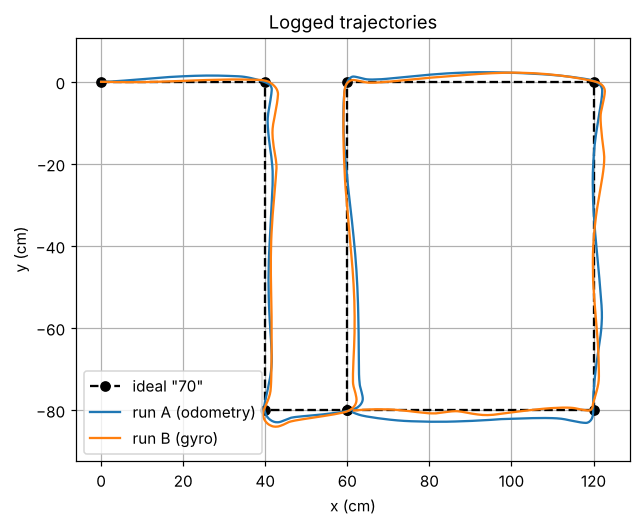

In [3]:
plt.figure(figsize=(6.5, 5))
plt.plot(X_ref, Y_ref, 'k--o', label='ideal "70"')
plt.plot(runs['A']['x'], runs['A']['y'], label='run A (odometry)')
plt.plot(runs['B']['x'], runs['B']['y'], label='run B (gyro)')
plt.axis('equal'); plt.xlabel('x (cm)'); plt.ylabel('y (cm)'); plt.legend(); plt.title('Logged trajectories')
plt.show()

Both logged trajectories lie on the ideal path, because the controller steers the robot's **own estimate** onto it.
The real errors only show up when the other method is recomputed from the same raw data (next step).

## 4.2 Offline recomputation: both methods from both logs (4 paths)

Run A: recomputed 'odo' vs logged -> max course diff 0.000°, max x,y diff 0.01 cm  (OK)
        'odo' vs 'gyro' estimate: max separation 10.4 cm, at the end 4.3 cm, final course difference -3.1°
Run B: recomputed 'gyro' vs logged -> max course diff 0.038°, max x,y diff 0.10 cm  (OK)
        'gyro' vs 'odo' estimate: max separation 9.6 cm, at the end 9.6 cm, final course difference +2.0°


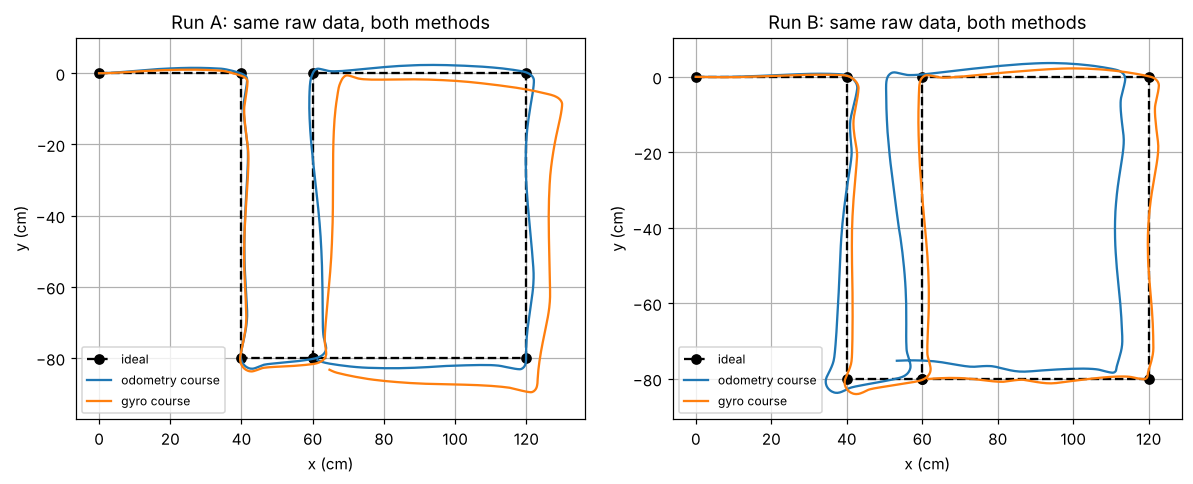

In [4]:
def recompute(d):
    thl, thr = np.radians(d['encL']), np.radians(d['encR'])
    path  = (thr + thl) * r / 2
    c_odo = (thr - thl) * r / B
    w     = np.radians(d['hdr']['GYRO_SIGN'] * (d['gz'] - d['hdr']['b0_mdps']) / 1000)   # rad/s, s = 0
    c_gyr = np.cumsum(w * d['dt_ms'] / 1000)
    dp = np.diff(path, prepend=0.0)
    out = {'path': path, 'dp': dp}
    for name, c in [('odo', c_odo), ('gyro', c_gyr)]:
        out[name] = dict(course=c, x=np.cumsum(dp * np.cos(c)), y=np.cumsum(dp * np.sin(c)))
    return out

rec = {k: recompute(d) for k, d in runs.items()}
for k, own in [('A', 'odo'), ('B', 'gyro')]:
    d, e = runs[k], rec[k]
    err_c = np.degrees(np.max(np.abs(e[own]['course'] - d['course'])))
    err_xy = np.max(np.hypot(e[own]['x'] - d['x'], e[own]['y'] - d['y']))
    other = 'gyro' if own == 'odo' else 'odo'
    sep = np.hypot(e['odo']['x'] - e['gyro']['x'], e['odo']['y'] - e['gyro']['y'])
    print(f"Run {k}: recomputed '{own}' vs logged -> max course diff {err_c:.3f}°, max x,y diff {err_xy:.2f} cm  (OK)")
    print(f"        '{own}' vs '{other}' estimate: max separation {sep.max():.1f} cm, at the end {sep[-1]:.1f} cm, "
          f"final course difference {np.degrees(e['gyro']['course'][-1] - e['odo']['course'][-1]):+.1f}°")

fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, k in zip(axs, 'AB'):
    ax.plot(X_ref, Y_ref, 'k--o', label='ideal')
    ax.plot(rec[k]['odo']['x'], rec[k]['odo']['y'], label='odometry course')
    ax.plot(rec[k]['gyro']['x'], rec[k]['gyro']['y'], label='gyro course')
    ax.set_title(f'Run {k}: same raw data, both methods'); ax.axis('equal'); ax.legend(fontsize=8)
    ax.set_xlabel('x (cm)'); ax.set_ylabel('y (cm)')
plt.tight_layout(); plt.show()

## 4.3 Course per segment

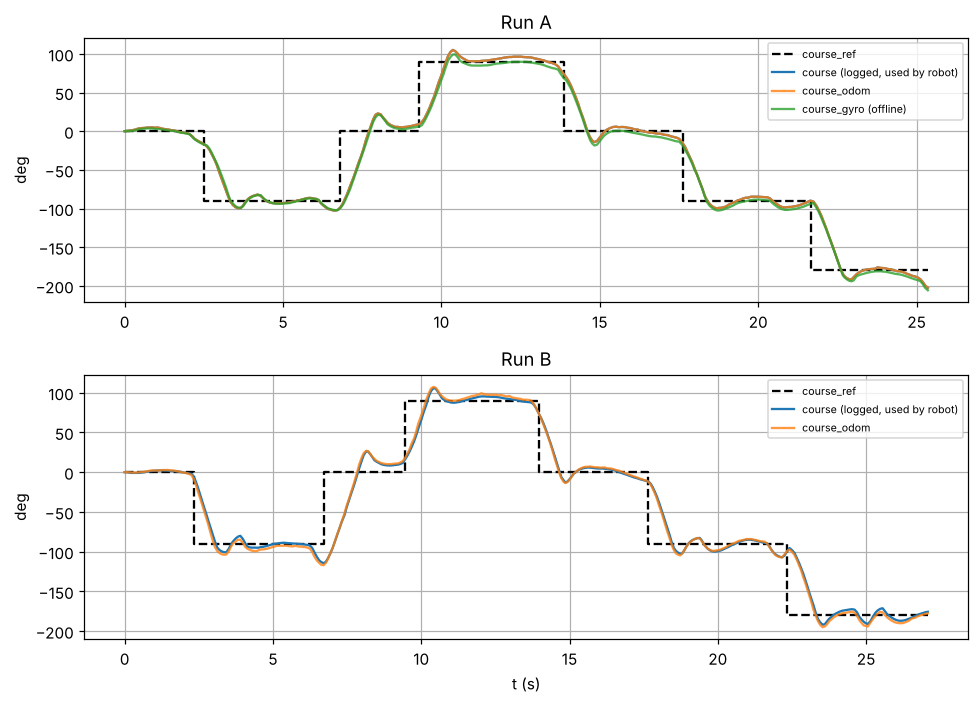

In [5]:
def segment_stats(d, e):
    rows = []
    for k in range(1, 8):
        drive = (d['seg'] == k) & (d['phase'] == 2)          # driving part of the segment (turn-in-place excluded)
        rows.append(dict(course=np.degrees(np.mean(d['course'][drive])),
                         odo=np.degrees(np.mean(e['odo']['course'][drive])),
                         gyro=np.degrees(np.mean(e['gyro']['course'][drive])),
                         path=e['dp'][d['seg'] == k].sum()))
    return pd.DataFrame(rows, index=range(1, 8))

S = {k: segment_stats(runs[k], rec[k]) for k in 'AB'}
cref_deg = np.degrees(course_ref)

fig, axs = plt.subplots(2, 1, figsize=(9, 6.5), sharex=False)
for ax, k in zip(axs, 'AB'):
    d, e = runs[k], rec[k]
    ax.step(d['t'], np.degrees(course_ref[d['seg'] - 1]), where='post', color='k', ls='--', label='course_ref')
    ax.plot(d['t'], np.degrees(d['course']), label='course (logged, used by robot)')
    ax.plot(d['t'], np.degrees(e['odo']['course']), label='course_odom', alpha=0.8)
    if k == 'A': ax.plot(d['t'], np.degrees(e['gyro']['course']), label='course_gyro (offline)', alpha=0.8)
    ax.set_title(f'Run {k}'); ax.set_ylabel('deg'); ax.legend(fontsize=7)
axs[-1].set_xlabel('t (s)'); plt.tight_layout(); plt.show()

## 4.4 Path per segment

In [6]:
for k in 'AB':
    tot = S[k]['path'].sum()
    print(f"Run {k}: total path {tot:.1f} cm vs ideal {path_ref.sum():.0f} cm -> error {tot - path_ref.sum():+.1f} cm "
          f"({(tot / path_ref.sum() - 1) * 100:+.1f} %)")

Run A: total path 429.7 cm vs ideal 420 cm -> error +9.7 cm (+2.3 %)
Run B: total path 428.5 cm vs ideal 420 cm -> error +8.5 cm (+2.0 %)


## Comparison table (one row per segment + summary)

In [7]:
T = pd.DataFrame({
    'course_ref (°)': cref_deg.round(1),
    'course A (°)': S['A']['course'].round(1).values, 'course B (°)': S['B']['course'].round(1).values,
    'd_course A (°)': (S['A']['course'] - cref_deg).round(1).values, 'd_course B (°)': (S['B']['course'] - cref_deg).round(1).values,
    'path_ref (cm)': path_ref.round(1),
    'path A (cm)': S['A']['path'].round(1).values, 'path B (cm)': S['B']['path'].round(1).values,
    'd_path A (cm)': (S['A']['path'] - path_ref).round(1).values, 'd_path B (cm)': (S['B']['path'] - path_ref).round(1).values,
}, index=pd.Index(range(1, 8), name='segment'))
summary = {c: '' for c in T.columns}
summary.update({'d_course A (°)': f"mean |·| {T['d_course A (°)'].abs().mean():.1f}",
                'd_course B (°)': f"mean |·| {T['d_course B (°)'].abs().mean():.1f}",
                'path_ref (cm)': f"{path_ref.sum():.0f}",
                'path A (cm)': f"{S['A']['path'].sum():.1f}", 'path B (cm)': f"{S['B']['path'].sum():.1f}",
                'd_path A (cm)': f"{(S['A']['path'].sum() / path_ref.sum() - 1) * 100:+.1f} %",
                'd_path B (cm)': f"{(S['B']['path'].sum() / path_ref.sum() - 1) * 100:+.1f} %"})
T = pd.concat([T.astype(object), pd.DataFrame([summary], index=pd.Index(['summary'], name='segment'))])
display(T)

,course_ref (°),course A (°),course B (°),d_course A (°),d_course B (°),path_ref (cm),path A (cm),path B (cm),d_path A (cm),d_path B (cm)
segment,,,,,,,,,,
1,0.0,-0.2,0.6,-0.2,0.6,40.0,38.6,38.7,-1.4,-1.3
2,-90.0,-91.2,-92.8,-1.2,-2.8,80.0,80.7,82.2,0.7,2.2
3,0.0,7.8,10.7,7.8,10.7,20.0,22.3,24.2,2.3,4.2
4,90.0,93.1,91.6,3.1,1.6,80.0,82.9,81.0,2.9,1.0
5,0.0,-0.5,-0.1,-0.5,-0.1,60.0,61.4,61.0,1.4,1.0
6,-90.0,-92.4,-92.3,-2.4,-2.3,80.0,80.9,81.6,0.9,1.6
7,-180.0,-183.2,-180.7,-3.2,-0.7,60.0,63.0,59.8,3.0,-0.2
summary,,,,mean |·| 2.6,mean |·| 2.7,420,429.7,428.5,+2.3 %,+2.0 %


### Final errors relative to the last waypoint (60, −80)

In [8]:
# Robot's own estimate stops within the 2 cm acceptance radius by design, so the estimate alone says little.
# The other method, recomputed from the same raw data, shows how far the estimate could be off.
# MEASURED: fill in the real final position measured on the floor with a tape (cm), e.g. {'A': (58, -86), 'B': (61, -81)}
MEASURED = {'A': None, 'B': None}

rows = []
for k, own, other in [('A', 'odo', 'gyro'), ('B', 'gyro', 'odo')]:
    d, e = runs[k], rec[k]
    fin = lambda x, y: np.hypot(x - X_ref[-1], y - Y_ref[-1])
    rows.append({'run': k,
                 'estimate final error (cm)': round(fin(d['x'][-1], d['y'][-1]), 1),
                 f'other method final error (cm)': round(fin(e[other]['x'][-1], e[other]['y'][-1]), 1),
                 'measured final error (cm)': (round(fin(*MEASURED[k]), 1) if MEASURED[k] else 'measure'),
                 'final course error, last segment mean (°)': round(S[k]['course'].iloc[-1] - cref_deg[-1], 1),
                 'final course error, last sample (°)': round(np.degrees(d['course'][-1]) - cref_deg[-1], 1)})
display(pd.DataFrame(rows).set_index('run'))

,estimate final error (cm),other method final error (cm),measured final error (cm),"final course error, last segment mean (°)","final course error, last sample (°)"
run,,,,,
A,1.5,5.7,measure,-3.2,-22.6
B,1.6,8.3,measure,-0.7,4.4


## 4.5 Error growth over the segments

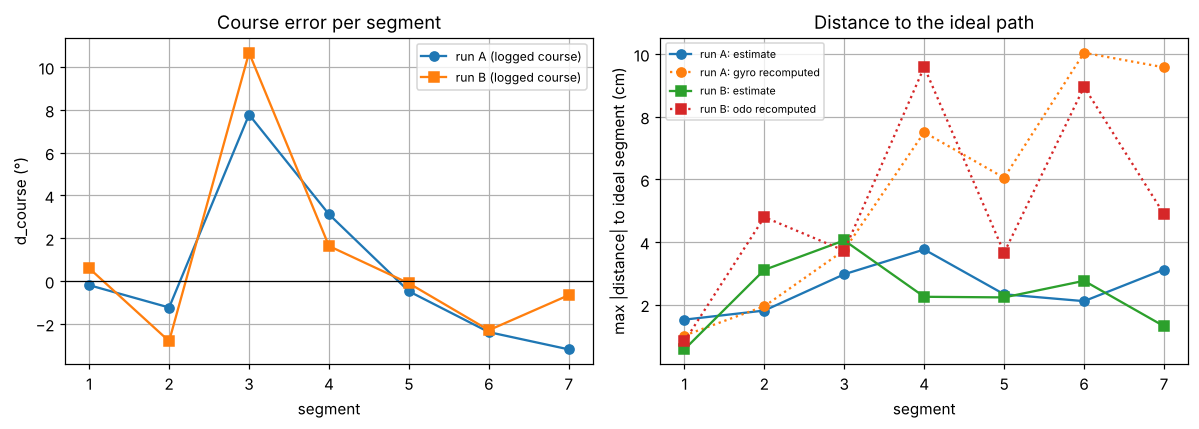

In [9]:
def cross_track(x, y, seg):
    i = seg - 1
    c = np.arctan2(Y_ref[i + 1] - Y_ref[i], X_ref[i + 1] - X_ref[i])
    return -(x - X_ref[i]) * np.sin(c) + (y - Y_ref[i]) * np.cos(c)

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for k, mk in [('A', 'o-'), ('B', 's-')]:
    axs[0].plot(range(1, 8), S[k]['course'] - cref_deg, mk, label=f'run {k} (logged course)')
for k, own, other, mk in [('A', 'odo', 'gyro', 'o-'), ('B', 'gyro', 'odo', 's-')]:
    d, e = runs[k], rec[k]
    for name, x, y, ls in [('estimate', d['x'], d['y'], mk), (f'{other} recomputed', e[other]['x'], e[other]['y'], mk + '-')]:
        dist = np.abs(cross_track(x, y, d['seg']))
        axs[1].plot(range(1, 8), [dist[d['seg'] == s].max() for s in range(1, 8)], ls.replace('--', ':'),
                    label=f'run {k}: {name}')
axs[0].axhline(0, color='k', lw=0.8); axs[0].set_xlabel('segment'); axs[0].set_ylabel('d_course (°)')
axs[0].set_title('Course error per segment'); axs[0].legend(fontsize=8)
axs[1].set_xlabel('segment'); axs[1].set_ylabel('max |distance| to ideal segment (cm)')
axs[1].set_title('Distance to the ideal path'); axs[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## Analysis

**Which run is closer?** Judged by the logged course, the two runs are practically equal: mean |d_course| is 2.6° for A and 2.7° for B, and the total path error is +2.3 % (A) vs +2.0 % (B). That similarity is expected. The controller always steers the robot's *own* estimate onto the ideal path, so the logged x, y and course look good in both runs, and the robot believes it finished within 2 cm of the last waypoint. The real difference shows up only when the other method is recomputed from the same raw data (4.2). In run A, the gyro course says the odometry pose was off by up to 10.4 cm (4.3 cm at the end). In run B, the odometry course says the gyro pose was off by up to 9.6 cm (9.6 cm at the end). Which estimate was right can only be settled by the measured final position (fill in `MEASURED`) and the videos.

**Why are path errors similar while course errors differ?** `path` comes from the encoders in both runs, with the same r and the same wheels, so it has the same error (+2.0 to 2.3 %, about +9 cm over 420 cm). Only `course` changes between the runs. Each segment is also a little longer than ideal because the robot overshoots inside the 2 cm acceptance radius and corrects.

**Which error source dominated?** In both logs the gyro and encoder courses agree on straight segments but separate at the turns in place. In run A the gap grows to −3.1° by the end, and in run B to +2.0°. The jumps in 4.5 happen right after the turns (segments 4 and 6). During fast in-place turns the encoder course can be wrong because of wheel slip or an inexact B. The gyro can be wrong because its scale factor was not corrected (s = 0) and its bias differed between runs (b0 = 1416 vs 1264 mdeg/s), which shows that recalibrating before every run is necessary. On straight segments both sources are small. The errors therefore build up in steps at the turns rather than steadily over time.

**Segment 3 stands out** (d_course +7.8° A, +10.7° B, d_path +2 to 4 cm). It is only 20 cm long. The controller starts driving once |courseAngle| < DRIVE_TOL = 0.15 rad (8.6°), and on such a short segment there is no time to remove that leftover angle. This is a controller effect, not a sensor error. The large "last sample" course error in run A (−22.6°) is a similar artefact: inside the acceptance radius the bearing to the waypoint swings quickly. The last-segment mean (−3.2° A, −0.7° B) is the meaningful final course error.

**How to combine them:** use the gyro for fast changes (turns, slip, bumps), where the encoders fail, and the encoders for slow changes, where gyro bias and scale errors build up. This is exactly the complementary filter `course = K·(course + gyro_inc) + (1 − K)·course_odom` of Lab 11.

*Note: the loop period was about 73 ms (median), not the ~10 ms aimed for, because the log line is written to a file every cycle.*
